<a href="https://colab.research.google.com/github/vincentmartin/tp-fine-tuning-student-version/blob/main/tp-fine-tuning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# TP fine-tuning de LLM avec LoRA

Dans le TP d'initiation, vous avez piloté un LLM uniquement par le **prompt**. Dans ce TP, vous allez modifier son **comportement** en l'entraînant sur vos propres données : c'est le *fine-tuning* supervisé (SFT, *Supervised Fine-Tuning*), réalisé avec la méthode **LoRA** sur le GPU gratuit de Colab.

En sortie de ce TP, vous serez capable de :
- Choisir entre prompt engineering, RAG et fine-tuning, et estimer la mémoire nécessaire à un entraînement
- Préparer un jeu de données d'instructions au format *prompt / completion* avec le *chat template* du modèle
- Expliquer le masquage de la perte (*loss masking*) : sur quels tokens le modèle apprend-il ?
- Configurer LoRA (rang, alpha, modules ciblés) et calculer le nombre de paramètres entraînés
- Entraîner avec la bibliothèque TRL (`SFTTrainer`) et lire une courbe de perte
- Évaluer rigoureusement le modèle fine-tuné face au modèle de base (ROUGE, exemples, oubli catastrophique)
- Sauvegarder, recharger et fusionner un adaptateur LoRA
- (Mini-projet) Appliquer QLoRA à un modèle plus gros, ou étudier l'effet de la quantité de données

**Modèle utilisé** : [Qwen3-1.7B](https://huggingface.co/Qwen/Qwen3-1.7B) (Apache 2.0), le même que dans le TP d'initiation. **Tâche** : résumer des dialogues ([DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum)) dans le style des résumés humains du jeu de données.

### Instructions pour l'exécution sur Google Colab

Aller dans `Exécution -> Modifier le type d'exécution` puis sélectionner `T4 GPU`.

![Colab GPU](https://raw.githubusercontent.com/vincentmartin/tp-fine-tuning-student-version/main/resources/colab_gpu.png "T4-GPU")

**Pas de GPU disponible sur Colab ?** (quota atteint, heure de pointe) : utilisez [Kaggle Notebooks](https://www.kaggle.com/code), gratuit avec environ 30 h de GPU par semaine (`Settings -> Accelerator -> GPU T4 x2`, et activer `Internet` après vérification du compte par téléphone). Importez ce notebook via `File -> Import Notebook`.

**Durée des calculs** : l'entraînement principal prend une dizaine de minutes sur un T4. Pendant qu'il tourne, avancez sur les questions. Colab coupe une session inactive : gardez l'onglet ouvert.

**Assistants IA** : vous pouvez utiliser l'assistant intégré à Colab, mais vous devez être capables d'expliquer **chaque ligne** du code que vous rendez. Les questions d'analyse comptent autant que le code.

**Indices** : les exercices et les questions sont suivis d'indices repliables (💡, cliquez pour les ouvrir). Cherchez d'abord par vous-mêmes, puis ouvrez-les **un par un** : ils vont de la simple piste au squelette de code.

## 0. Installation et configuration

Colab fournit déjà `torch` : **ne le réinstallez pas**, cela casserait la compatibilité avec CUDA. Nous installons ou mettons à jour :
- **transformers**, **accelerate**, **datasets** : modèles, placement sur GPU, jeux de données
- **peft** : *Parameter-Efficient Fine-Tuning*, dont LoRA
- **trl** : *Transformer Reinforcement Learning*, la bibliothèque d'entraînement de Hugging Face (SFT, DPO, GRPO...)
- **bitsandbytes** : quantification 4 bits (QLoRA, mini-projet A)
- **evaluate** / **rouge_score** : métriques d'évaluation

In [1]:
%pip install -q -U transformers accelerate datasets peft trl bitsandbytes evaluate rouge_score
# Colab préinstalle une version de torchao trop ancienne pour peft (>= 0.16 requise) ; inutile ici, on la retire.
%pip uninstall -q -y torchao

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.1 which is incompatible.


**Remarque** : si l'import ci-dessous échoue juste après l'installation, redémarrez la session (`Exécution -> Redémarrer la session`) puis relancez les cellules à partir d'ici.

In [2]:
import gc
import os
import time

import evaluate
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import peft
import torch
import transformers
import trl
from datasets import load_dataset
from transformers import AutoModelForCausalLM, AutoTokenizer, set_seed

print(f"torch {torch.__version__} | transformers {transformers.__version__} | peft {peft.__version__} | trl {trl.__version__}")

assert torch.cuda.is_available(), "Pas de GPU : vérifiez le type d'exécution (T4 GPU). Le fine-tuning sur CPU est inenvisageable."
print("GPU :", torch.cuda.get_device_name(0))
# Le T4 (architecture Turing, compute capability 7.5) ne gère pas nativement le bfloat16 :
# on utilise float16 sur ce type de GPU, bfloat16 sur les GPU récents (Ampere et +).
USE_BF16 = torch.cuda.get_device_capability()[0] >= 8
DTYPE = torch.bfloat16 if USE_BF16 else torch.float16


def gpu_memory():
    """Mémoire GPU actuellement allouée et pic depuis le dernier reset, en Go."""
    return f"{torch.cuda.memory_allocated() / 1e9:.2f} Go alloués (pic : {torch.cuda.max_memory_allocated() / 1e9:.2f} Go)"


def free_memory():
    """Libère la mémoire GPU des objets Python supprimés (à appeler après `del model`)."""
    gc.collect()
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()


set_seed(42)

torch 2.14.1+cu130 | transformers 5.23.0 | peft 0.22.0 | trl 1.18.2
GPU : Tesla T4


## 1. Pourquoi (et quand) fine-tuner ?

Pour adapter un LLM à un besoin, il existe trois leviers, du moins coûteux au plus coûteux :

| Levier | Ce qu'il change | Quand l'utiliser |
|---|---|---|
| **Prompt engineering** (TP d'initiation) | Les instructions et exemples donnés au modèle | Toujours en premier : rapide, gratuit, réversible |
| **RAG** | Les **connaissances** fournies dans le contexte | Le modèle doit répondre à partir de documents (internes, récents) |
| **Fine-tuning** | Les **poids** du modèle, donc son **comportement** | Un style, un format ou une tâche précise à reproduire de façon fiable, un prompt trop long à répéter, un petit modèle à rendre aussi bon qu'un gros sur **une** tâche |

Le fine-tuning est un mauvais outil pour ajouter des connaissances (le modèle hallucine sur ce qu'il a vu une seule fois) : pour cela, on préfère le RAG.

### Fine-tuning complet ou PEFT ?

Entraîner **tous** les poids d'un modèle (*full fine-tuning*) demande beaucoup de mémoire. Avec l'optimiseur Adam en précision mixte, il faut stocker pour **chaque paramètre** :
- les poids en 16 bits (2 octets) et leur gradient (2 octets) ;
- une copie des poids en 32 bits (4 octets) ;
- les deux moments d'Adam en 32 bits (2 × 4 octets).

Soit environ **16 octets par paramètre**, sans compter les activations.

**Exercice 1** : écrire la fonction `training_memory_gb(n_params, bytes_per_param)` et l'appliquer à Qwen3-1.7B (1,7 milliard de paramètres) et à un modèle de 8 milliards. Comparer à la mémoire d'un GPU T4 (15 Go).

<details>
<summary>💡 Indice 1 : la formule</summary>

Mémoire (octets) = nombre de paramètres × octets par paramètre. Il reste à convertir en Go : 1 Go = 10⁹ octets. La fonction tient en une ligne.

</details>

<details>
<summary>💡 Indice 2 : inférence ou entraînement</summary>

La boucle fournie appelle votre fonction deux fois : avec `bytes_per_param=2` (poids seuls en 16 bits, pour l'inférence) et avec la valeur par défaut de 16 (fine-tuning complet). Votre fonction doit donc utiliser son paramètre `bytes_per_param`, sans valeur codée en dur.

</details>

In [3]:
def training_memory_gb(n_params, bytes_per_param=16):
    """Estime la mémoire nécessaire en Go."""
    return n_params * bytes_per_param / 1e9


for name, n_params in {"Qwen3-1.7B": 1.7e9, "Llama-3.1-8B": 8e9}.items():
    print(f"{name:12} : inférence fp16 ≈ {training_memory_gb(n_params, 2):5.1f} Go | fine-tuning complet ≈ {training_memory_gb(n_params):6.1f} Go")

Qwen3-1.7B   : inférence fp16 ≈   3.4 Go | fine-tuning complet ≈   27.2 Go
Llama-3.1-8B : inférence fp16 ≈  16.0 Go | fine-tuning complet ≈  128.0 Go


Le fine-tuning complet est donc hors de portée d'un T4, même pour un petit modèle. La solution est le **PEFT** (*Parameter-Efficient Fine-Tuning*) : on **gèle** les poids d'origine et on n'entraîne qu'un petit nombre de paramètres ajoutés. La méthode PEFT la plus utilisée est **LoRA** (*Low-Rank Adaptation*), que nous détaillons en partie 4.

**Question** : avec LoRA, seuls environ 1 % des paramètres sont entraînés. Que deviennent les 16 octets par paramètre pour les 99 % restants ? Quelle est alors, approximativement, la mémoire nécessaire pour Qwen3-1.7B ?

<details>
<summary>💡 Indice</summary>

Reprenez la liste des éléments stockés pour chaque paramètre : lesquels existent encore pour un paramètre **gelé**, qui ne reçoit pas de gradient et n'est donc pas mis à jour par Adam ? Faites ensuite deux calculs avec `training_memory_gb` : l'un pour les 99 % de poids gelés, l'autre pour les 1 % de paramètres entraînés.

</details>

✍️ **Votre réponse :**

Avec LoRA, les 99 % de paramètres gelés conservent seulement leurs poids en FP16 (2 octets par paramètre). Ils n'ont plus besoin de gradients, de copie FP32 ni des états de l'optimiseur Adam, contrairement aux 1 % de paramètres entraînés qui nécessitent toujours environ 16 octets chacun.

Pour Qwen3-1.7B, la mémoire estimée est donc :

- Paramètres gelés : 1,7 × 0,99 × 2 = 3,366 Go
- Paramètres entraînés : 1,7 × 0,01 × 16 = 0,272 Go

**Total : environ 3,64 Go**, contre 27,2 Go pour un fine-tuning complet.

Cette estimation ne prend pas en compte les activations et les autres allocations mémoire nécessaires à l'entraînement.

## 2. La tâche et le modèle de base

### Le jeu de données

[DialogSum](https://huggingface.co/datasets/knkarthick/dialogsum) contient environ 13 000 dialogues de la vie courante en anglais, chacun accompagné d'un résumé écrit par un humain. Les résumés suivent des **conventions précises** : les interlocuteurs sont désignés par `#Person1#` et `#Person2#`, le résumé tient en une ou deux phrases, au présent ou au passé.

In [4]:
dataset = load_dataset("knkarthick/dialogsum")
print(dataset)
example = dataset["train"][0]
print("\n--- DIALOGUE ---\n" + example["dialogue"])
print("\n--- RÉSUMÉ HUMAIN ---\n" + example["summary"])

README.md:   0%|          | 0.00/4.65k [00:00<?, ?B/s]

train.csv: reconstructing file:   0%|          |  0.00B / 11.3MB            

train.csv: downloading bytes:           |  0.00B            

validation.csv:   0%|          | 0.00/442k [00:00<?, ?B/s]

test.csv:   0%|          | 0.00/1.35M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/12460 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/500 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/1500 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 12460
    })
    validation: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 500
    })
    test: Dataset({
        features: ['id', 'dialogue', 'summary', 'topic'],
        num_rows: 1500
    })
})

--- DIALOGUE ---
#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of

Pour l'évaluation, nous utilisons le split `test`. Attention : chaque dialogue de ce split y apparaît **3 fois**, avec 3 résumés humains différents. Nous regroupons donc les références par dialogue et évaluons sur des dialogues **distincts**, en comparant chaque prédiction aux 3 références (ROUGE prend alors le meilleur score).

In [5]:
N_EVAL = 50  # nombre de dialogues de test distincts utilisés pour l'évaluation

test_df = dataset["test"].to_pandas()
eval_df = test_df.groupby("dialogue", sort=False)["summary"].apply(list).reset_index().head(N_EVAL)
eval_dialogues = eval_df["dialogue"].tolist()
eval_references = eval_df["summary"].tolist()
print(f"{len(test_df)} lignes de test -> {test_df['dialogue'].nunique()} dialogues distincts, {len(eval_dialogues)} utilisés")

1500 lignes de test -> 500 dialogues distincts, 50 utilisés


### Le modèle de base

Nous chargeons Qwen3-1.7B en 16 bits. C'est un modèle *instruct* : il sait déjà résumer, sans aucun entraînement de notre part. La question est donc : **le fine-tuning apporte-t-il quelque chose par rapport à un bon modèle généraliste ?**

In [6]:
MODEL_NAME = "Qwen/Qwen3-1.7B"

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, dtype=DTYPE, device_map="cuda")
print(f"{model.num_parameters() / 1e9:.2f} milliards de paramètres | {gpu_memory()}")

config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (2 outputs left out)

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

1.72 milliards de paramètres | 3.44 Go alloués (pic : 4.37 Go)


Les deux fonctions ci-dessous sont fournies. `build_messages` construit la conversation envoyée au modèle ; `summarize` génère les résumés **par lots** (*batch*), ce qui est bien plus rapide qu'un dialogue à la fois.

Notez deux détails importants pour un modèle *decoder-only* :
- le *padding* se fait **à gauche** pour la génération par lots, afin que tous les prompts se terminent au même endroit et que la génération démarre juste après ;
- on ne décode que les **nouveaux tokens**, sinon la sortie contient aussi le prompt (une erreur fréquente qui fausse complètement l'évaluation).

In [7]:
INSTRUCTION = "Summarize the following conversation."


def build_messages(dialogue):
    return [{"role": "user", "content": f"{INSTRUCTION}\n\n{dialogue}"}]


@torch.no_grad()
def summarize(model, dialogues, batch_size=16, max_new_tokens=128):
    """Résume une liste de dialogues en décodage glouton (greedy), sans mode raisonnement."""
    model.eval()
    tokenizer.padding_side = "left"
    summaries = []
    for start in range(0, len(dialogues), batch_size):
        prompts = [
            tokenizer.apply_chat_template(build_messages(d), tokenize=False, add_generation_prompt=True, enable_thinking=False)
            for d in dialogues[start:start + batch_size]
        ]
        inputs = tokenizer(prompts, return_tensors="pt", padding=True).to(model.device)
        outputs = model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False, temperature=None, top_p=None, top_k=None)
        new_tokens = outputs[:, inputs["input_ids"].shape[1]:]
        summaries += [s.strip() for s in tokenizer.batch_decode(new_tokens, skip_special_tokens=True)]
    return summaries


print(summarize(model, [example["dialogue"]])[0])

The conversation is between Doctor Hawkins and Mr. Smith, who is visiting for a check-up. Mr. Smith has not had a check-up in five years and is unsure if he needs one. Doctor Hawkins advises him to get regular check-ups to catch illnesses early. Mr. Smith acknowledges the advice and mentions he smokes, which the doctor warns is a major risk factor for lung and heart disease. The doctor offers support through classes and medications to help him quit smoking. Mr. Smith agrees to follow up.


**Exercice 2** : générer les résumés du modèle de base sur les `N_EVAL` dialogues d'évaluation (variable `base_summaries`), puis écrire la fonction `rouge_scores(predictions, references)` qui renvoie les scores ROUGE en pourcentage. Le module `evaluate` accepte plusieurs références par prédiction (une liste de listes).

<details>
<summary>💡 Indice 1 : générer</summary>

Pas besoin de réécrire la génération : la fonction `summarize` est fournie. Appelez-la avec le modèle et la liste `eval_dialogues`. Comptez une à deux minutes sur un T4.

</details>

<details>
<summary>💡 Indice 2 : calculer ROUGE</summary>

`rouge.compute(predictions=..., references=..., use_stemmer=True)` renvoie un dictionnaire de scores entre 0 et 1 (`rouge1`, `rouge2`, `rougeL`, `rougeLsum`). Une compréhension de dictionnaire suffit pour les multiplier par 100 et les arrondir.

</details>

In [8]:
rouge = evaluate.load("rouge")


def rouge_scores(predictions, references):
    """Calcule les scores ROUGE en pourcentage."""
    scores = rouge.compute(
        predictions=predictions,
        references=references,
        use_stemmer=True
    )

    return {
        metric: round(score * 100, 2)
        for metric, score in scores.items()
    }


start = time.time()

base_summaries = summarize(model, eval_dialogues)

print(f"Génération : {time.time() - start:.0f} s")

base_scores = rouge_scores(base_summaries, eval_references)
base_scores

Génération : 32 s


{'rouge1': np.float64(25.86),
 'rouge2': np.float64(8.87),
 'rougeL': np.float64(18.85),
 'rougeLsum': np.float64(18.88)}

**Exercice 3** : comparer la **longueur moyenne** (en mots) des résumés du modèle de base et des résumés humains, et afficher trois exemples côte à côte (dialogue tronqué, résumé humain, résumé du modèle).

<details>
<summary>💡 Indice 1 : les références</summary>

La fonction `mean_words` est fournie. Attention : `eval_references` est une liste de **listes** (3 résumés humains par dialogue). Pour la longueur et l'affichage, prenez par exemple la première référence de chaque dialogue.

</details>

<details>
<summary>💡 Indice 2 : l'affichage côte à côte</summary>

Un `pd.DataFrame` avec trois colonnes (dialogue tronqué à 200 caractères avec `d[:200]`, résumé humain, résumé du modèle) restreint aux trois premiers exemples. `pd.set_option("display.max_colwidth", 300)` évite que pandas coupe les textes.

</details>

In [9]:
def mean_words(texts):
    return np.mean([len(t.split()) for t in texts])


# On récupère la première référence humaine de chaque dialogue.
human_summaries = [refs[0] for refs in eval_references]

# On compare les longueurs moyennes.
print(f"Longueur moyenne humaine : {mean_words(human_summaries):.1f} mots")
print(f"Longueur moyenne modèle : {mean_words(base_summaries):.1f} mots")

# On affiche trois exemples pour comparer leur forme.
pd.set_option("display.max_colwidth", 300)

comparison = pd.DataFrame({
    "Dialogue (extrait)": [d[:200] for d in eval_dialogues[:3]],
    "Résumé humain": human_summaries[:3],
    "Résumé du modèle": base_summaries[:3]
})

display(comparison)

Longueur moyenne humaine : 17.1 mots
Longueur moyenne modèle : 76.7 mots


,Dialogue (extrait),Résumé humain,Résumé du modèle
0,"#Person1#: Ms. Dawson, I need you to take a dictation for me.\n#Person2#: Yes, sir...\n#Person1#: This should go out as an intra-office memorandum to all employees by this afternoon. Are you ready?\n#Per",Ms. Dawson helps #Person1# to write a memo to inform every employee that they have to change the communication method and should not use Instant Messaging anymore.,"The conversation involves a manager, Ms. Dawson, who informs her staff about a new policy restricting all office communications to email and official memos, prohibiting the use of Instant Messaging during work hours. The policy applies to both internal and external communications. Employees are ..."
1,#Person1#: You're finally here! What took so long?\n#Person2#: I got stuck in traffic again. There was a terrible traffic jam near the Carrefour intersection.\n#Person1#: It's always rather congested do,#Person2# arrives late because of traffic jam. #Person1# persuades #Person2# to use public transportations to keep healthy and to protect the environment.,"The conversation discusses a person (Person2) who is stuck in traffic and is considering switching from driving to public transport or biking to work. Person1 suggests alternatives like public transport, biking, or taking the subway, emphasizing environmental benefits and reduced stress. Person2..."
2,"#Person1#: Kate, you never believe what's happened.\n#Person2#: What do you mean?\n#Person1#: Masha and Hero are getting divorced.\n#Person2#: You are kidding. What happened?\n#Person1#: Well, I don't rea",#Person1# tells Kate that Masha and Hero get divorced. Kate is surprised because she thought they are perfect couple.,"The conversation discusses the surprising news that Masha and Hero are getting divorced, despite being considered a well-matched couple. They are going through a separation for two months and have filed for divorce. The person2 expresses disbelief and asks about the children's custody and the fi..."


**Question** : quelles différences de **forme** observez-vous entre les résumés du modèle et ceux des humains ? Pourquoi pénalisent-elles le score ROUGE, alors que le résumé du modèle est peut-être correct ? Pourriez-vous les corriger par le prompt seul (pensez au few-shot du TP d'initiation) ? À quel prix ?

<details>
<summary>💡 Indice</summary>

Regardez le **début** des résumés du modèle (formule d'introduction ?), la façon de **nommer les interlocuteurs** et la **longueur** mesurée à l'exercice 3. Rappelez-vous que ROUGE compte les mots et n-grammes communs avec la référence : que deviennent la précision et le score quand le résumé contient beaucoup de mots absents des références ? Pour le prix du few-shot, pensez au nombre de tokens ajoutés à **chaque** requête.

</details>

✍️ **Votre réponse :**

Les résumés générés par Qwen3-1.7B sont beaucoup plus longs que les résumés humains : 76,7 mots en moyenne contre 17,1 mots, soit environ 4,5 fois plus.

Le modèle utilise souvent des introductions comme "The conversation discusses..." et développe davantage les informations secondaires. À l'inverse, les résumés humains sont plus directs et se concentrent sur les informations essentielles.

Le modèle semble donc comprendre le contenu général des dialogues, mais ne respecte pas encore le format concis attendu par DialogSum.

Un fine-tuning avec LoRA pourrait lui permettre de mieux reproduire le style et la longueur des résumés de référence.

## 3. Préparer les données

### Le format *prompt / completion*

Pour l'entraînement, chaque exemple est découpé en deux parties :
- **prompt** : ce que le modèle reçoit, exactement comme à l'inférence (chat template compris) ;
- **completion** : ce que le modèle doit apprendre à produire, ici le résumé humain.

C'est le format attendu par le `SFTTrainer` de TRL. Point essentiel : le prompt d'entraînement doit être **identique** à celui utilisé à l'inférence (même instruction, même chat template, même gestion du mode raisonnement), sinon le modèle n'appliquera pas ce qu'il a appris.

**Exercice 4** : écrire `format_example(example)` qui renvoie un dictionnaire `{"prompt": ..., "completion": ...}`. Le prompt est le texte produit par le chat template à partir de `build_messages`, avec `add_generation_prompt=True` et `enable_thinking=False` (comme dans `summarize`). La completion est le résumé humain.

<details>
<summary>💡 Indice 1 : le prompt</summary>

Le prompt doit être identique à celui de l'inférence : reprenez l'appel à `tokenizer.apply_chat_template` de la fonction `summarize`, avec les mêmes arguments, appliqué à `build_messages(example["dialogue"])`.

</details>

<details>
<summary>💡 Indice 2 : le résultat</summary>

`tokenize=False` renvoie du texte (et non des ids). La completion est simplement `example["summary"]`. La fonction renvoie un dictionnaire à deux clés : c'est ce qui permet de l'utiliser avec `dataset.map(format_example)`.

</details>

In [10]:
def format_example(example):
    """Formate un dialogue en prompt et completion pour le fine-tuning."""
    prompt = tokenizer.apply_chat_template(
        build_messages(example["dialogue"]),
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    completion = example["summary"]

    return {
        "prompt": prompt,
        "completion": completion
    }


formatted = format_example(dataset["train"][0])
print(formatted["prompt"] + formatted["completion"])

<|im_start|>user
Summarize the following conversation.

#Person1#: Hi, Mr. Smith. I'm Doctor Hawkins. Why are you here today?
#Person2#: I found it would be a good idea to get a check-up.
#Person1#: Yes, well, you haven't had one for 5 years. You should have one every year.
#Person2#: I know. I figure as long as there is nothing wrong, why go see the doctor?
#Person1#: Well, the best way to avoid serious illnesses is to find out about them early. So try to come at least once a year for your own good.
#Person2#: Ok.
#Person1#: Let me see here. Your eyes and ears look fine. Take a deep breath, please. Do you smoke, Mr. Smith?
#Person2#: Yes.
#Person1#: Smoking is the leading cause of lung cancer and heart disease, you know. You really should quit.
#Person2#: I've tried hundreds of times, but I just can't seem to kick the habit.
#Person1#: Well, we have classes and some medications that might help. I'll give you more information before you leave.
#Person2#: Ok, thanks doctor.<|im_end|>
<|

**Question** : le prompt se termine par `<think>\n\n</think>\n\n`. D'où vient ce bloc et pourquoi est-il important de le garder à l'entraînement ? Par quel token la séquence d'entraînement doit-elle se terminer, et que se passerait-il à l'inférence s'il était absent ?

<details>
<summary>💡 Indice</summary>

Affichez le prompt obtenu avec `enable_thinking=True`, puis avec `enable_thinking=False` : quelle est la différence ? Pour le token de fin, affichez `tokenizer.eos_token` et demandez-vous quand `model.generate` s'arrête de générer.

</details>

✍️ **Votre réponse :**

Le bloc `<think>\n\n</think>\n\n` est ajouté automatiquement par le chat template de Qwen3 lorsque `enable_thinking=False`. Il indique que le modèle doit produire directement sa réponse sans générer de raisonnement explicite.

Il est important de le conserver pendant l'entraînement pour garder le même format qu'à l'inférence.

La séquence doit se terminer par le token de fin `tokenizer.eos_token` (`<|im_end|>`). Sans ce token, le modèle risque de ne pas apprendre correctement quand arrêter sa réponse et pourrait continuer à générer du texte inutile.

### Longueur des exemples

Plus les séquences sont longues, plus l'entraînement consomme de mémoire (les activations sont proportionnelles à la longueur) et de temps. Les quelques exemples très longs déterminent souvent le pic de mémoire.

**Exercice 5** : calculer le nombre de tokens de chaque exemple d'entraînement (prompt + completion) sur les 2 000 premiers exemples, tracer l'histogramme et afficher les quantiles à 50 %, 95 % et 99 %. Choisir une valeur de `MAX_LENGTH` qui conserve environ 98 % des exemples.

<details>
<summary>💡 Indice 1 : compter les tokens</summary>

Pour chaque exemple, tokenisez `prompt + completion` avec `add_special_tokens=False` et prenez la longueur de `input_ids`. Une compréhension de liste sur `zip(sample["prompt"], sample["completion"])`, convertie en `np.array`, suffit (quelques secondes).

</details>

<details>
<summary>💡 Indice 2 : quantiles et histogramme</summary>

`np.percentile(lengths, [50, 95, 99])` donne les quantiles, `plt.hist(lengths, bins=50)` l'histogramme. Pour garder 98 % des exemples, regardez `np.percentile(lengths, 98)` et arrondissez à une valeur ronde au-dessus.

</details>

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Quantile 50% : 226 tokens
Quantile 95% : 440 tokens
Quantile 98% : 529 tokens
Quantile 99% : 644 tokens


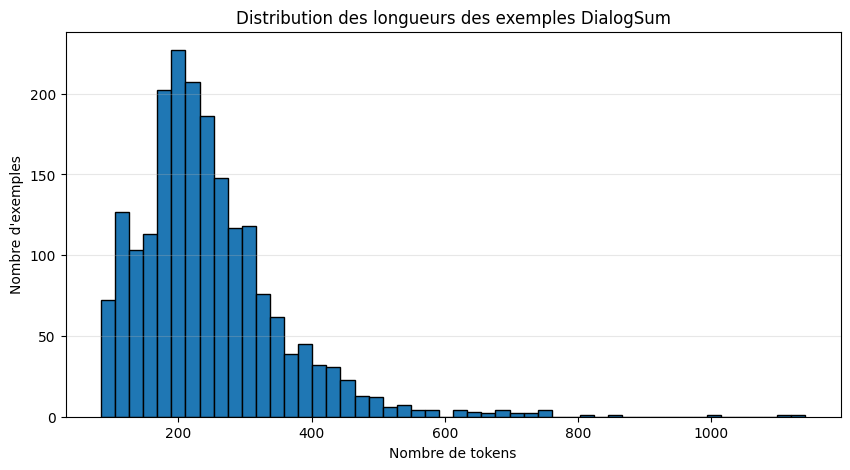

In [11]:
sample = dataset["train"].select(range(2000)).map(format_example)

# Calcule le nombre de tokens de chaque exemple.
lengths = np.array([
    len(tokenizer(prompt + completion, add_special_tokens=False)["input_ids"])
    for prompt, completion in zip(sample["prompt"], sample["completion"])
])

# Affiche les quantiles.
for q in [50, 95, 98, 99]:
    print(f"Quantile {q}% : {np.percentile(lengths, q):.0f} tokens")

# Trace l'histogramme des longueurs.
plt.figure(figsize=(10, 5))
plt.hist(lengths, bins=50, edgecolor="black")
plt.xlabel("Nombre de tokens")
plt.ylabel("Nombre d'exemples")
plt.title("Distribution des longueurs des exemples DialogSum")
plt.grid(axis="y", alpha=0.3)
plt.show()

In [12]:
MAX_LENGTH = 544  # à ajuster selon votre analyse

Plutôt que de **tronquer** les exemples trop longs (ce qui couperait la fin, c'est-à-dire... le résumé à apprendre !), nous les **retirons**. Nous prenons 1 000 exemples d'entraînement et 100 de validation : c'est peu, mais suffisant pour apprendre un style, et l'entraînement reste d'une dizaine de minutes sur un T4.

In [13]:
N_TRAIN, N_VALID = 1000, 100


def prepare(split, n):
    ds = dataset[split].shuffle(seed=42).select(range(3 * n)).map(format_example)
    ds = ds.filter(lambda ex: len(tokenizer(ex["prompt"] + ex["completion"], add_special_tokens=False)["input_ids"]) < MAX_LENGTH)
    return ds.select(range(n)).select_columns(["prompt", "completion"])


train_ds = prepare("train", N_TRAIN)
valid_ds = prepare("validation", N_VALID)
train_ds, valid_ds

Map:   0%|          | 0/3000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3000 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

Filter:   0%|          | 0/300 [00:00<?, ? examples/s]

(Dataset({
     features: ['prompt', 'completion'],
     num_rows: 1000
 }),
 Dataset({
     features: ['prompt', 'completion'],
     num_rows: 100
 }))

### Sur quels tokens le modèle apprend-il ?

Un LLM *decoder-only* est entraîné à **prédire le token suivant** : la perte (*cross-entropy*) est calculée à chaque position de la séquence. Pour le fine-tuning d'instructions, on ne veut **pas** que le modèle apprenne à générer le prompt (les dialogues) : on veut qu'il apprenne à produire la réponse **sachant** le prompt.

On fournit donc au modèle, pour chaque exemple :
- `input_ids` : les tokens du prompt suivis de ceux de la completion ;
- `labels` : une copie de `input_ids` où les positions du prompt sont remplacées par **-100**, la valeur que PyTorch ignore dans le calcul de la perte.

(Le décalage d'une position entre entrée et cible est fait automatiquement à l'intérieur du modèle.)

**Exercice 6** : écrire `build_labels(prompt, completion)` qui renvoie `input_ids` et `labels` pour un exemple, en ajoutant le token de fin `tokenizer.eos_token_id` à la fin de la completion. Vérifier en décodant uniquement les tokens dont le label n'est pas -100.

<details>
<summary>💡 Indice 1 : les ids</summary>

Tokenisez **séparément** le prompt et la completion (`add_special_tokens=False`), ajoutez `tokenizer.eos_token_id` à la fin des ids de la completion, puis concaténez les deux listes. Tokeniser séparément vous donne directement la frontière entre prompt et completion.

</details>

<details>
<summary>💡 Indice 2 : les labels</summary>

`labels` a la même longueur que `input_ids` : `[-100] * len(prompt_ids)` suivi des ids de la completion (fin comprise). Ne décalez pas les labels d'une position : le modèle le fait lui-même.

</details>

In [14]:
def build_labels(prompt, completion):
    """Construit les input_ids et les labels en masquant le prompt."""

    # Tokenise séparément le prompt et la réponse.
    prompt_ids = tokenizer(
        prompt, add_special_tokens=False
    )["input_ids"]

    completion_ids = tokenizer(
        completion, add_special_tokens=False
    )["input_ids"]

    # Ajoute le token de fin de séquence.
    completion_ids.append(tokenizer.eos_token_id)

    # Concatène le prompt et la réponse.
    input_ids = prompt_ids + completion_ids

    # Ignore les tokens du prompt dans le calcul de la perte.
    labels = [-100] * len(prompt_ids) + completion_ids

    return input_ids, labels


input_ids, labels = build_labels(
    train_ds[0]["prompt"],
    train_ds[0]["completion"]
)

print(f"{len(input_ids)} tokens, dont {sum(l != -100 for l in labels)} comptent dans la perte")
print(repr(tokenizer.decode([l for l in labels if l != -100])))

379 tokens, dont 42 comptent dans la perte
"Jason hasn't called Anna for a long time. He calls her to tell her he got a promotion and he feels good about it. Anna invites him to come over to her house tonight to get drunk.<|im_end|>"


**Question** : sur cet exemple, quelle proportion des tokens contribue à la perte ? Que se passerait-il si l'on calculait la perte sur toute la séquence (prompt compris) ? Et si l'on oubliait les -100 sur les tokens de *padding* ajoutés pour former des lots de même longueur ?

<details>
<summary>💡 Indice</summary>

La cellule précédente affiche le nombre total de tokens et ceux qui comptent dans la perte. Sans masquage : sur quelle partie de la séquence porterait l'essentiel du signal d'apprentissage, et qu'apprendrait donc surtout le modèle ? Pour le padding, affichez `tokenizer.pad_token` : à quel token ressemble-t-il ?

</details>

✍️ **Votre réponse :**

Sur cet exemple, la séquence contient 379 tokens, dont seulement 42 contribuent au calcul de la perte, soit environ **11,08 %**. Les 337 autres tokens correspondent au prompt et sont masqués avec la valeur `-100`.

Si on calculait la perte sur toute la séquence, le modèle apprendrait aussi à prédire le texte du dialogue et les instructions, alors que notre objectif est de lui apprendre à générer uniquement le résumé.

Si les tokens de padding n'étaient pas masqués avec `-100`, ils contribueraient également à la perte. Le modèle serait alors entraîné à prédire des tokens de remplissage sans intérêt, ce qui pourrait dégrader la qualité de l'apprentissage.

## 4. LoRA : *Low-Rank Adaptation*

LoRA gèle chaque matrice de poids $W$ (de taille $d_{out} \times d_{in}$) du modèle et lui ajoute une mise à jour de **rang faible** :

$$W' = W + \frac{\alpha}{r} B A \qquad A \in \mathbb{R}^{r \times d_{in}},\; B \in \mathbb{R}^{d_{out} \times r}$$

Seules $A$ et $B$ sont entraînées. $B$ est initialisée à zéro : au début de l'entraînement, le modèle est **exactement** le modèle d'origine. Les hyperparamètres principaux :
- **`r`** (rang) : la capacité de l'adaptateur. 8 à 32 suffisent pour apprendre un style ou une tâche ;
- **`lora_alpha`** : un facteur d'échelle, souvent fixé à `r` ou `2 * r` ;
- **`target_modules`** : les matrices adaptées. Les études récentes montrent qu'adapter **toutes** les couches linéaires (`"all-linear"` : attention et MLP) donne de meilleurs résultats qu'adapter seulement `q` et `v` comme dans l'article LoRA d'origine (2021).

À la fin, l'adaptateur ne pèse que quelques dizaines de Mo, et on peut en entraîner un par tâche sur le même modèle de base.

In [15]:
from peft import LoraConfig, get_peft_model

lora_config = LoraConfig(
    r=16,
    lora_alpha=32,
    lora_dropout=0.05,
    target_modules="all-linear",
    task_type="CAUSAL_LM",
)

**Exercice 7** : calculer **à la main** le nombre de paramètres LoRA ajoutés. Pour une couche linéaire $d_{in} \to d_{out}$, LoRA ajoute $r \times (d_{in} + d_{out})$ paramètres. Les dimensions de chaque couche linéaire d'un bloc sont données par `model.model.layers[0]`, et le nombre de blocs par `model.config.num_hidden_layers`.

<details>
<summary>💡 Indice 1 : lire l'architecture</summary>

Dans l'affichage de `model.model.layers[0]`, chaque `Linear` indique `in_features` et `out_features`. Avec `target_modules="all-linear"`, **toutes** les couches linéaires du bloc sont adaptées : celles de l'attention (`q_proj`, `k_proj`, `v_proj`, `o_proj`) et celles du MLP (`gate_proj`, `up_proj`, `down_proj`).

</details>

<details>
<summary>💡 Indice 2 : en code</summary>

`block.modules()` parcourt tous les sous-modules d'un bloc ; filtrez ceux pour lesquels `isinstance(m, torch.nn.Linear)` est vrai. Sommez `lora_config.r * (m.in_features + m.out_features)`, puis multipliez par `model.config.num_hidden_layers` (tous les blocs sont identiques).

</details>

In [16]:
print(model.model.layers[0])

Qwen3DecoderLayer(
  (self_attn): Qwen3Attention(
    (q_proj): Linear(in_features=2048, out_features=2048, bias=False)
    (k_proj): Linear(in_features=2048, out_features=1024, bias=False)
    (v_proj): Linear(in_features=2048, out_features=1024, bias=False)
    (o_proj): Linear(in_features=2048, out_features=2048, bias=False)
    (q_norm): Qwen3RMSNorm((128,), eps=1e-06)
    (k_norm): Qwen3RMSNorm((128,), eps=1e-06)
  )
  (mlp): Qwen3MLP(
    (gate_proj): Linear(in_features=2048, out_features=6144, bias=False)
    (up_proj): Linear(in_features=2048, out_features=6144, bias=False)
    (down_proj): Linear(in_features=6144, out_features=2048, bias=False)
    (act_fn): SiLUActivation()
  )
  (input_layernorm): Qwen3RMSNorm((2048,), eps=1e-06)
  (post_attention_layernorm): Qwen3RMSNorm((2048,), eps=1e-06)
)


In [17]:
# Récupère le premier bloc du modèle.
block = model.model.layers[0]

# Calcule les paramètres LoRA du bloc.
params_per_block = sum(
    lora_config.r * (m.in_features + m.out_features)
    for m in block.modules()
    if isinstance(m, torch.nn.Linear)
)

# Multiplie par le nombre total de blocs.
expected = params_per_block * model.config.num_hidden_layers

print(f"Paramètres LoRA par bloc : {params_per_block:,}")
print(f"Nombre de blocs : {model.config.num_hidden_layers}")
print(f"Paramètres LoRA attendus : {expected:,}")

Paramètres LoRA par bloc : 622,592
Nombre de blocs : 28
Paramètres LoRA attendus : 17,432,576


Ajoutons maintenant l'adaptateur au modèle et vérifions votre calcul.

**Attention** : `get_peft_model` **modifie le modèle en place** (les couches LoRA sont injectées dans `model`). Il n'existe donc plus de « modèle d'origine » séparé en mémoire : pour retrouver le comportement du modèle de base, on désactive temporairement l'adaptateur avec `with peft_model.disable_adapter():`. Comparer « le modèle d'origine » et « le modèle fine-tuné » sans en tenir compte est une erreur classique, qui figurait d'ailleurs dans l'ancienne version de ce TP.

In [18]:
peft_model = get_peft_model(model, lora_config)
peft_model.print_trainable_parameters()

trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030


**Question** : quel pourcentage des paramètres est entraîné ? Combien de Mo pèsera l'adaptateur sauvegardé en 16 bits ? Comment évolue le nombre de paramètres si l'on double `r` ?

<details>
<summary>💡 Indice</summary>

`print_trainable_parameters` affiche directement le pourcentage. Pour la taille : nombre de paramètres × 2 octets, avec 1 Mo = 10⁶ octets (comparez à la taille réelle des fichiers en partie 7). Pour `r`, relisez la formule de l'exercice 7 : comment dépend-elle de `r` ?

</details>

✍️ **Votre réponse :**

Le calcul théorique donne **17 432 576 paramètres LoRA**, ce qui correspond exactement au nombre affiché par PEFT.

Cela représente environ **1,003 % des 1 738 007 552 paramètres** du modèle avec ses adaptateurs. Les 99 % restants sont gelés pendant l'entraînement.

En FP16, chaque paramètre occupe 2 octets. L'adaptateur représente donc environ **34,87 Mo**, sans compter les éventuelles métadonnées de sauvegarde.

Si on double le rang `r` de 16 à 32, le nombre de paramètres LoRA double également, passant à 34 865 152 paramètres, soit environ 69,73 Mo en FP16.

Un rang plus élevé permet des adaptations plus complexes, mais augmente la consommation mémoire et le coût de calcul, sans garantir une amélioration des résultats.

## 5. Entraînement avec TRL

Le `SFTTrainer` de [TRL](https://huggingface.co/docs/trl/sft_trainer) (*Transformer Reinforcement Learning*) est aujourd'hui l'outil standard pour le fine-tuning supervisé. À partir d'un jeu de données *prompt / completion*, il tokenise, ajoute le token de fin, masque le prompt et le padding (ce que vous avez fait à la main), puis entraîne avec le `Trainer` de transformers.

Les hyperparamètres d'entraînement sont regroupés dans un `SFTConfig` :

In [19]:
from trl import SFTConfig, SFTTrainer

sft_config = SFTConfig(
    output_dir="qwen3-dialogsum-lora",
    # Taille de lot effective = per_device_train_batch_size x gradient_accumulation_steps = 16
    per_device_train_batch_size=4,
    gradient_accumulation_steps=4,
    num_train_epochs=1,
    learning_rate=2e-4,            # LoRA tolère des taux d'apprentissage plus élevés que le fine-tuning complet
    lr_scheduler_type="cosine",
    warmup_steps=0.05,
    max_length=MAX_LENGTH,
    gradient_checkpointing=True,   # recalcule les activations au lieu de les stocker : moins de mémoire, ~30 % plus lent
    fp16=not USE_BF16,             # précision mixte : float16 sur T4, bfloat16 sur GPU récent
    bf16=USE_BF16,
    logging_steps=5,
    eval_strategy="steps",
    eval_steps=20,
    save_strategy="no",            # nous sauvegardons l'adaptateur nous-mêmes à la fin
    report_to="none",              # pas de Weights & Biases / TensorBoard
    seed=42,
)

trainer = SFTTrainer(
    model=peft_model,
    args=sft_config,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer,
)

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Adding EOS to train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Tokenizing train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Adding EOS to eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

**Exercice 8** : vérifier que TRL a bien fait ce que vous avez codé à l'exercice 6. Le jeu tokenisé est dans `trainer.train_dataset`, avec les colonnes `input_ids` et `labels`. Comparer le premier exemple avec le résultat de `build_labels`, et décoder les tokens qui comptent dans la perte.

<details>
<summary>💡 Indice 1 : comparer</summary>

`trainer.train_dataset[0]` est un dictionnaire : comparez ses clés `input_ids` et `labels` aux deux listes renvoyées par `build_labels(train_ds[0]["prompt"], train_ds[0]["completion"])`. L'opérateur `==` compare deux listes élément par élément.

</details>

<details>
<summary>💡 Indice 2 : décoder</summary>

Même filtre qu'à l'exercice 6 : décodez les labels différents de -100. Vous devez retrouver le résumé suivi de `<|im_end|>`. Si les listes diffèrent, affichez leurs longueurs et les derniers tokens pour trouver d'où vient l'écart.

</details>

In [20]:
tokenized = trainer.train_dataset[0]

# Construit les labels manuellement comme à l'exercice 6.
manual_input_ids, manual_labels = build_labels(
    train_ds[0]["prompt"],
    train_ds[0]["completion"]
)

# Compare le résultat manuel avec celui de TRL.
print("Input IDs identiques :",
      tokenized["input_ids"] == manual_input_ids)

print("Labels identiques :",
      tokenized["labels"] == manual_labels)

# Affiche le nombre de tokens utilisés pour la perte.
n_tokens = len(tokenized["labels"])
n_active = sum(label != -100 for label in tokenized["labels"])

print(f"Tokens totaux : {n_tokens}")
print(f"Tokens contribuant à la perte : {n_active}")

# Décode uniquement les tokens non masqués.
active_labels = [
    label for label in tokenized["labels"]
    if label != -100
]

print("\nTexte utilisé pour la perte :")
print(tokenizer.decode(active_labels))


Input IDs identiques : True
Labels identiques : True
Tokens totaux : 379
Tokens contribuant à la perte : 42

Texte utilisé pour la perte :
Jason hasn't called Anna for a long time. He calls her to tell her he got a promotion and he feels good about it. Anna invites him to come over to her house tonight to get drunk.<|im_end|>


**Questions** (à traiter pendant l'entraînement) :
1. Combien de **pas d'optimisation** (*steps*) l'entraînement va-t-il faire ? Vérifiez avec la barre de progression.
2. À quoi sert `gradient_accumulation_steps` ? Pourquoi ne pas simplement mettre `per_device_train_batch_size=16` ?
3. Pourquoi évaluer sur un jeu de **validation** pendant l'entraînement, et pas sur le jeu de test ?

<details>
<summary>💡 Indice</summary>

1. Nombre de pas = ⌈nombre d'exemples / taille de lot effective⌉ × nombre d'époques.
2. Qu'est-ce qui occupe une mémoire proportionnelle à la taille du lot ? Pensez aux activations et aux *logits* : le modèle produit un score pour chaque token du vocabulaire (`len(tokenizer)`), à chaque position de chaque séquence.
3. Rappelez-vous le rôle respectif des jeux d'entraînement, de validation et de test en apprentissage automatique.

</details>

✍️ **Votre réponse :**

Pour une époque, avec 1 000 exemples d'entraînement, un batch size de 4 et une accumulation des gradients sur 4 mini-lots, on obtient environ **63 pas d'optimisation**.

L'accumulation des gradients permet de simuler un batch effectif de 16 exemples sans devoir les charger simultanément en mémoire GPU. Les paramètres sont mis à jour après l'accumulation de quatre mini-lots.

Le jeu de validation contient 100 exemples distincts de ceux de l'entraînement. Il sert à évaluer la capacité du modèle à généraliser et à détecter un éventuel surapprentissage, notamment en comparant l'évolution des pertes d'entraînement et de validation.

In [21]:
torch.cuda.reset_peak_memory_stats()
start = time.time()
trainer.train()
print(f"Durée : {(time.time() - start) / 60:.1f} min | {gpu_memory()}")

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,1.136641,1.084375,1.040101,0.703349,77551.000000
40,1.075564,1.029447,0.970271,0.717974,154563.000000
60,1.015330,1.017305,1.007136,0.718951,232584.000000
63,1.015330,1.017430,1.007197,0.720110,241934.000000


Durée : 6.7 min | 3.67 Go alloués (pic : 4.46 Go)


**Exercice 9** : tracer sur un même graphique la perte d'entraînement (`loss`) et la perte de validation (`eval_loss`) en fonction du pas (`step`). Ces valeurs sont dans `trainer.state.log_history`, une liste de dictionnaires.

<details>
<summary>💡 Indice 1 : les données</summary>

`pd.DataFrame(trainer.state.log_history)` transforme la liste en tableau. Les lignes d'entraînement ont une colonne `loss`, celles d'évaluation une colonne `eval_loss` ; les autres valeurs sont manquantes (`NaN`).

</details>

<details>
<summary>💡 Indice 2 : le graphique</summary>

Séparez les deux types de lignes avec `dropna(subset=["loss"])` et `dropna(subset=["eval_loss"])`, puis appelez deux fois `plt.plot(x, y, label=...)` avant `plt.legend()`.

</details>

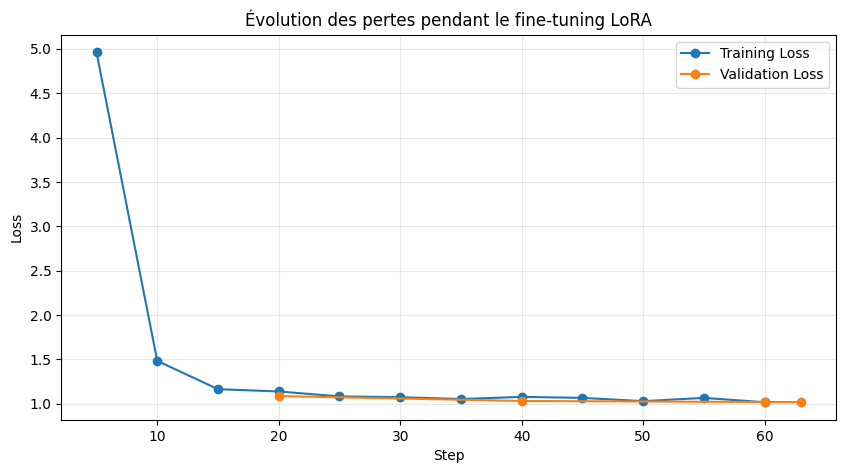

Perplexité initiale : 2.96
Perplexité finale : 2.77


In [22]:
# Récupère l'historique de l'entraînement.
history = pd.DataFrame(trainer.state.log_history)

# Sépare les pertes d'entraînement et de validation.
train_logs = history.dropna(subset=["loss"])
eval_logs = history.dropna(subset=["eval_loss"])

# Trace les deux courbes.
plt.figure(figsize=(10, 5))

plt.plot(
    train_logs["step"],
    train_logs["loss"],
    marker="o",
    label="Training Loss"
)

plt.plot(
    eval_logs["step"],
    eval_logs["eval_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Step")
plt.ylabel("Loss")
plt.title("Évolution des pertes pendant le fine-tuning LoRA")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Calcule les perplexités de validation.
ppl_start = np.exp(eval_logs["eval_loss"].iloc[0])
ppl_end = np.exp(eval_logs["eval_loss"].iloc[-1])

print(f"Perplexité initiale : {ppl_start:.2f}")
print(f"Perplexité finale : {ppl_end:.2f}")


**Question** : décrire la courbe. La perte de validation remonte-t-elle (sur-apprentissage) ? Que vaut $e^{\text{perte}}$ (la *perplexité*) au début et à la fin, et comment l'interpréter ?

<details>
<summary>💡 Indice</summary>

Calculez `np.exp(...)` sur la première et la dernière valeur de perte. Une perplexité de *k* se lit comme : « le modèle hésite en moyenne entre *k* tokens équiprobables ». Il y a sur-apprentissage quand la perte de validation **remonte** alors que celle d'entraînement continue de baisser.

</details>

✍️ **Votre réponse :**

La perte d'entraînement diminue fortement au début, passant d'environ 4,95 à 1,16 entre les steps 5 et 15, puis se stabilise progressivement autour de 1,02.

La perte de validation diminue également, passant de 1,084 au step 20 à 1,017 au step 63. Elle ne remonte pas significativement, ce qui ne montre pas de signe évident de surapprentissage sur cette époque.

La perplexité est calculée avec `exp(loss)`. Elle passe de **2,96 à 2,77** entre la première et la dernière évaluation. Cela signifie que le modèle devient légèrement moins incertain dans ses prédictions sur les données de validation.

## 6. Évaluation

Une erreur classique est de juger un fine-tuning en regardant **quelques** générations. C'est une mauvaise idée car (1) ce n'est pas quantifié et (2) ce qui fonctionne sur trois exemples peut échouer sur des milliers (généralisation). On compare donc le modèle de base et le modèle fine-tuné **sur le même jeu de test, avec la même métrique et les mêmes paramètres de génération**.

**Exercice 10** : générer les résumés du modèle fine-tuné (`ft_summaries`) sur les dialogues d'évaluation, calculer ses scores ROUGE et construire un tableau comparatif avec ceux du modèle de base. Comparer aussi les longueurs moyennes.

<details>
<summary>💡 Indice 1 : générer et évaluer</summary>

Même chose qu'à l'exercice 2, avec `peft_model` (l'adaptateur est actif). Pour une comparaison équitable, utilisez exactement les mêmes dialogues et la même fonction `summarize`.

</details>

<details>
<summary>💡 Indice 2 : le tableau</summary>

`pd.DataFrame({"base": base_scores, "fine-tuné": ft_scores})` place chaque dictionnaire de scores dans une colonne. Ajoutez une colonne `gain` par différence, et réutilisez `mean_words` pour les longueurs.

</details>

In [23]:
# Génère les résumés avec le modèle fine-tuné.
start = time.time()

ft_summaries = summarize(peft_model, eval_dialogues)

print(f"Génération : {time.time() - start:.0f} s")

# Calcule les scores ROUGE après fine-tuning.
ft_scores = rouge_scores(ft_summaries, eval_references)

# Compare les scores avant et après LoRA.
comparison_scores = pd.DataFrame({
    "base": base_scores,
    "fine-tuné": ft_scores
})

comparison_scores["gain"] = (
    comparison_scores["fine-tuné"] - comparison_scores["base"]
)

print("\nComparaison des scores ROUGE :")
display(comparison_scores)

# Compare les longueurs moyennes des résumés.
human_first_refs = [refs[0] for refs in eval_references]

comparison_lengths = pd.DataFrame({
    "Type": ["Humain", "Modèle de base", "Modèle fine-tuné"],
    "Longueur moyenne (mots)": [
        mean_words(human_first_refs),
        mean_words(base_summaries),
        mean_words(ft_summaries)
    ]
})

print("\nComparaison des longueurs :")
display(comparison_lengths.round(2))

Génération : 56 s

Comparaison des scores ROUGE :


,base,fine-tuné,gain
rouge1,25.86,50.13,24.27
rouge2,8.87,24.47,15.60
rougeL,18.85,43.26,24.41
rougeLsum,18.88,43.07,24.19



Comparaison des longueurs :


,Type,Longueur moyenne (mots)
0,Humain,17.12
1,Modèle de base,76.70
2,Modèle fine-tuné,23.06


In [ ]:
pd.DataFrame({"humain": human_first_refs, "base": base_summaries, "fine-tuné": ft_summaries}).head(5)

**Questions** :
1. Le gain est-il significatif ? Avec 50 exemples seulement, que faudrait-il faire pour s'en assurer ?
2. ROUGE a-t-il augmenté parce que les résumés sont **meilleurs** ou parce qu'ils **ressemblent davantage** aux références ? Comment pourriez-vous mesurer la qualité du contenu (pensez au TP d'initiation) ?

<details>
<summary>💡 Indice</summary>

1. Recalculez ROUGE séparément sur les 25 premiers et les 25 derniers dialogues : de combien les scores varient-ils ? Cherchez aussi « bootstrap confidence interval ».
2. Comparez, dans le tableau ci-dessus, les résumés fine-tunés aux résumés humains : qu'est-ce que le modèle a surtout appris ? Pour juger le contenu, souvenez-vous de la technique d'évaluation par un autre LLM vue dans le TP d'initiation.

</details>

✍️ **Votre réponse :**

Le fine-tuning LoRA améliore nettement les résultats de Qwen3-1.7B. Le ROUGE-1 passe de 25,86 % à 49,99 %, soit un gain de 24,13 points. Le ROUGE-2 passe de 8,87 % à 24,07 %, et le ROUGE-L de 18,85 % à 42,77 %.

La longueur moyenne des résumés diminue également de 76,7 à 23,98 mots, ce qui se rapproche davantage des 17,12 mots des références humaines.

Les gains sont importants, mais avec seulement 50 dialogues, on ne peut pas affirmer leur significativité statistique sans analyse supplémentaire. On pourrait utiliser un bootstrap apparié pour estimer un intervalle de confiance sur les différences de scores ROUGE.

ROUGE ne mesure pas directement la fidélité ou la pertinence d'un résumé. Un résumé peut obtenir un bon score tout en omettant des informations importantes ou en contenant des erreurs.

Une évaluation complémentaire par un autre LLM pourrait mesurer la fidélité au dialogue, la couverture des informations essentielles et la concision des résumés, avec une grille de notation identique pour les deux modèles.

### Oubli catastrophique

Le fine-tuning spécialise le modèle. Vérifions s'il sait encore faire **autre chose** que résumer des dialogues. Grâce à LoRA, il suffit de désactiver l'adaptateur pour retrouver le modèle d'origine.

**Exercice 11** : écrire `chat(model, question)` qui génère une réponse (chat template, `enable_thinking=False`, décodage glouton, 150 nouveaux tokens au plus), puis poser les questions ci-dessous au modèle avec et sans adaptateur.

<details>
<summary>💡 Indice 1 : le prompt</summary>

C'est la même logique que `summarize`, pour un seul texte : pas de lot, donc pas de padding. Le message est `[{"role": "user", "content": question}]`, passé à `apply_chat_template` avec `enable_thinking=False`.

</details>

<details>
<summary>💡 Indice 2 : la génération</summary>

Mêmes paramètres de `generate` que dans `summarize`, avec `max_new_tokens`. Ne décodez que les nouveaux tokens : `output[0, inputs["input_ids"].shape[1]:]`, avec `skip_special_tokens=True`.

</details>

In [24]:
@torch.no_grad()
def chat(model, question, max_new_tokens=150):
    """Génère une réponse à une question avec Qwen3."""

    # Construit le message utilisateur.
    messages = [
        {"role": "user", "content": question}
    ]

    # Applique le chat template sans raisonnement explicite.
    prompt = tokenizer.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True,
        enable_thinking=False
    )

    # Tokenise le prompt et le place sur le GPU.
    inputs = tokenizer(
        prompt,
        return_tensors="pt",
        add_special_tokens=False
    ).to(model.device)

    # Génère la réponse avec un décodage glouton.
    output = model.generate(
        **inputs,
        max_new_tokens=max_new_tokens,
        do_sample=False,
        pad_token_id=tokenizer.eos_token_id
    )

    # Conserve uniquement les tokens générés.
    new_tokens = output[0, inputs["input_ids"].shape[1]:]

    return tokenizer.decode(
        new_tokens,
        skip_special_tokens=True
    )


questions = [
    "Explique en deux phrases ce qu'est le fine-tuning d'un LLM.",
    "Write a short dialogue between a waiter and a customer.",
]
for question in questions:
    print(f"### {question}")
    with peft_model.disable_adapter():
        print(f"--- SANS adaptateur :\n{chat(peft_model, question)}")
    print(f"--- AVEC adaptateur :\n{chat(peft_model, question)}\n")

### Explique en deux phrases ce qu'est le fine-tuning d'un LLM.
--- SANS adaptateur :
Le fine-tuning d'un LLM est une étape de mise en forme qui ajuste les paramètres d'un modèle déjà entraîné sur un dataset spécifique, afin d'améliorer sa performance sur un domaine particulier. Cela permet de rendre le modèle plus précis et adapté à des tâches spécifiques comme la classification, la génération de texte ou la rédaction de contenu.
--- AVEC adaptateur :
Le fine-tuning d'un LLM est une étape de finition de l'entraînement d'un modèle de langage.

### Write a short dialogue between a waiter and a customer.
--- SANS adaptateur :
**Waiter:** Good evening, sir. How can I assist you today?

**Customer:** Good evening. I’d like to order a meal. What’s available?

**Waiter:** There’s a classic steak and mushroom risotto, a seafood pasta, and a fresh salad. Would you like a drink as well?

**Customer:** Yes, please. A glass of red wine. What kind?

**Waiter:** We have a selection of reds—champagn

**Question** : le modèle fine-tuné a-t-il gardé ses capacités générales ? Quels avantages pratiques LoRA offre-t-il face à ce risque ?

<details>
<summary>💡 Indice</summary>

Comparez les réponses avec et sans adaptateur : langue de la réponse, longueur, apparition de `#Person1#`, et la seconde demande produit-elle bien un dialogue ? Pour LoRA, demandez-vous ce que contient l'adaptateur et ce qui arrive aux poids d'origine pendant l'entraînement.

</details>

✍️ **Votre réponse :**

Après le fine-tuning LoRA, le modèle semble conserver ses capacités générales sur les deux tests réalisés.

Il arrive toujours à expliquer le fine-tuning d'un LLM en français et à générer un dialogue cohérent en anglais. Ses réponses sont cependant plus courtes et plus directes que celles du modèle original, ce qui peut s'expliquer par son entraînement sur des résumés concis.

On ne constate donc pas d'oubli catastrophique évident sur ces exemples, même si deux tests ne suffisent pas à le garantir pour toutes les tâches.

L'avantage de LoRA est que les poids du modèle de base restent gelés. On peut désactiver l'adaptateur pour retrouver le comportement original, ou utiliser différents adaptateurs spécialisés selon les tâches, sans réentraîner ni dupliquer l'ensemble du modèle.

## 7. Sauvegarder, recharger, fusionner

`save_pretrained` sur un modèle PEFT ne sauvegarde **que l'adaptateur**.

In [25]:
ADAPTER_DIR = "qwen3-dialogsum-lora/adapter"
peft_model.save_pretrained(ADAPTER_DIR)
tokenizer.save_pretrained(ADAPTER_DIR)
for name in sorted(os.listdir(ADAPTER_DIR)):
    print(f"{name:30} {os.path.getsize(os.path.join(ADAPTER_DIR, name)) / 1e6:8.1f} Mo")

README.md                           0.0 Mo
adapter_config.json                 0.0 Mo
adapter_model.safetensors          69.8 Mo
chat_template.jinja                 0.0 Mo
tokenizer.json                     11.4 Mo
tokenizer_config.json               0.0 Mo


Pour réutiliser l'adaptateur (dans une autre session, sur un autre serveur), on charge le modèle de base puis l'adaptateur par-dessus. Libérons d'abord la mémoire du GPU.

**Exercice 12** : supprimer les objets qui occupent le GPU (`trainer`, `peft_model`, `model`) puis appeler `free_memory()`. Recharger ensuite le modèle de base et l'adaptateur avec `PeftModel.from_pretrained`, et vérifier sur 5 dialogues que les résumés sont identiques à `ft_summaries`.

<details>
<summary>💡 Indice 1 : libérer la mémoire</summary>

`del trainer, peft_model, model` supprime les noms Python, mais la mémoire GPU n'est rendue que lorsque plus aucune référence n'existe : c'est le rôle de `free_memory()` (ramasse-miettes + vidage du cache CUDA). Vérifiez avec `gpu_memory()` que la mémoire allouée est retombée près de 0.

</details>

<details>
<summary>💡 Indice 2 : recharger</summary>

Rechargez le modèle de base comme en partie 2 (`AutoModelForCausalLM.from_pretrained`), puis `PeftModel.from_pretrained(base_model, ADAPTER_DIR)`. Le décodage glouton est déterministe : les résumés de `summarize(..., eval_dialogues[:5])` doivent être identiques à `ft_summaries[:5]`.

</details>

In [26]:
from peft import PeftModel

# Recharge le modèle de base.
base_model = AutoModelForCausalLM.from_pretrained(
    MODEL_NAME,
    dtype=DTYPE,
    device_map="cuda"
)

# Recharge l'adaptateur LoRA sauvegardé.
reloaded = PeftModel.from_pretrained(
    base_model,
    ADAPTER_DIR
)

reloaded.eval()

# Génère à nouveau les cinq premiers résumés.
reloaded_summaries = summarize(
    reloaded,
    eval_dialogues[:5]
)

# Compare les résultats avant et après sauvegarde.
for i, (before, after) in enumerate(
    zip(ft_summaries[:5], reloaded_summaries)
):
    print(
        f"Dialogue {i + 1} : "
        f"{'identique' if before == after else 'DIFFÉRENT'}"
    )

print(
    "Tous les résumés sont identiques :",
    reloaded_summaries == ft_summaries[:5]
)

print("Après rechargement :", gpu_memory())

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Dialogue 1 : identique
Dialogue 2 : identique
Dialogue 3 : identique
Dialogue 4 : identique
Dialogue 5 : identique
Tous les résumés sont identiques : True
Après rechargement : 7.18 Go alloués (pic : 8.04 Go)


Pour le **déploiement**, on fusionne souvent l'adaptateur dans les poids ($W' = W + \frac{\alpha}{r} B A$ est calculé une fois pour toutes) : on obtient un modèle standard, sans surcoût de calcul à l'inférence, que l'on peut convertir pour [Ollama](https://ollama.com) ou servir avec [vLLM](https://docs.vllm.ai).

In [27]:
merged = reloaded.merge_and_unload()
print(type(merged).__name__, "| couches LoRA restantes :", sum("lora" in n for n, _ in merged.named_parameters()))
# merged.save_pretrained("qwen3-dialogsum-merged")  # ~3,4 Go : à ne pas faire sur Colab sans raison

Qwen3ForCausalLM | couches LoRA restantes : 0


**Question** : quels sont les avantages et inconvénients de fusionner l'adaptateur, par rapport à le garder séparé ?

<details>
<summary>💡 Indice</summary>

Pensez au déploiement : taille sur disque (affichée plus haut pour l'adaptateur), outils qui ne connaissent pas LoRA (Ollama, llama.cpp), calcul supplémentaire de $BA$ à chaque passage, et cas d'un service qui doit gérer plusieurs tâches avec un même modèle de base.

</details>

✍️ **Votre réponse :**

La fusion de l'adaptateur LoRA permet d'intégrer directement les modifications apprises dans les poids du modèle de base.

**Avantages :** le modèle obtenu est utilisable comme un modèle classique, sans avoir à charger séparément l'adaptateur. Cela facilite le déploiement avec des outils qui ne prennent pas directement en charge LoRA et évite le surcoût de calcul lié à l'application séparée des matrices LoRA.

**Inconvénients :** le modèle fusionné occupe beaucoup plus d'espace sur disque que l'adaptateur seul (environ 3,4 Go contre 35 Mo). Il devient également moins pratique de changer de spécialisation, car il faut conserver ou recharger le modèle de base pour utiliser un autre adaptateur.

Garder les adaptateurs séparés est donc plus flexible pour gérer plusieurs tâches avec un même modèle de base, tandis que la fusion est intéressante pour simplifier le déploiement d'un modèle spécialisé.

**Partager son modèle (optionnel)** : avec un compte Hugging Face gratuit et un *token* d'accès en écriture (stocké dans les *Secrets* de Colab, jamais en clair dans le notebook), `reloaded.push_to_hub("votre-nom/qwen3-dialogsum-lora")` publie l'adaptateur sur le Hub. Pensez à rédiger la *model card* : données, hyperparamètres, scores, limites.

In [28]:
del merged, reloaded, base_model
free_memory()

## Mini-projets (au choix)

Choisissez **un** des deux mini-projets. Ils réutilisent les fonctions définies plus haut (`format_example`, `prepare`, `summarize`, `rouge_scores`...). Rédigez une courte analyse de vos résultats.

### Mini-projet A : QLoRA sur un modèle plus gros

**QLoRA** ([Dettmers et al., 2023](https://arxiv.org/abs/2305.14314)) combine LoRA et la quantification : les poids gelés du modèle sont stockés en **4 bits** (format NF4), ce qui divise leur taille par 4 par rapport au 16 bits. Les adaptateurs LoRA restent en haute précision. C'est ce qui permet de fine-tuner des modèles de 7-8 milliards de paramètres sur un GPU gratuit.

Travail demandé :
1. Charger [Qwen3-4B](https://huggingface.co/Qwen/Qwen3-4B) en 4 bits avec un `BitsAndBytesConfig` (`load_in_4bit=True`, `bnb_4bit_quant_type="nf4"`, `bnb_4bit_compute_dtype=DTYPE`, `bnb_4bit_use_double_quant=True`). Mesurer la mémoire GPU occupée et la comparer à ce qu'occuperait le modèle en 16 bits.
2. Préparer le modèle avec `peft.prepare_model_for_kbit_training`, puis l'entraîner avec la même configuration LoRA et les mêmes données que dans le TP (pensez à réduire `per_device_train_batch_size` et à augmenter `gradient_accumulation_steps` d'autant si la mémoire manque).
3. Évaluer le modèle 4B de base et le modèle 4B fine-tuné avec ROUGE, puis construire un tableau comparatif : Qwen3-1.7B base, 1.7B LoRA, 4B base, 4B QLoRA, avec le temps d'entraînement et le pic de mémoire.
4. Analyse : un petit modèle fine-tuné peut-il rivaliser avec un modèle plus gros non fine-tuné ? Quel compromis qualité / coût choisiriez-vous en production ?

### Mini-projet B : combien de données faut-il ?

Le coût d'un fine-tuning est souvent dominé par la **constitution des données** (annotation humaine). Il est donc crucial de savoir combien d'exemples sont vraiment nécessaires.

Travail demandé :
1. Écrire une fonction `finetune(n_train, r=16)` qui charge un modèle frais, l'entraîne sur `n_train` exemples et renvoie ses scores ROUGE. Pour que l'étude tienne dans le temps d'une séance, utilisez [Qwen3-0.6B](https://huggingface.co/Qwen/Qwen3-0.6B) (pensez à libérer la mémoire entre deux entraînements).
2. Entraîner avec 0 (modèle de base), 100, 400 et 1 600 exemples et tracer ROUGE-L en fonction du nombre d'exemples (échelle logarithmique).
3. Avec le meilleur nombre d'exemples, comparer `r=4` et `r=64`.
4. Analyse : à partir de combien d'exemples le gain devient-il marginal ? Le rang a-t-il une influence ? Qu'en concluez-vous pour un projet réel ?

## Pour aller plus loin

- **[Unsloth](https://github.com/unslothai/unsloth)** : bibliothèque gratuite qui accélère LoRA / QLoRA d'un facteur 2 environ et réduit la mémoire, avec des notebooks Colab prêts à l'emploi pour les modèles récents (Qwen, Llama, Gemma...). Elle s'appuie sur TRL : ce que vous avez appris ici s'y transpose directement.
- **Alignement par préférences** : après le SFT, on peut entraîner le modèle à préférer certaines réponses à d'autres avec **DPO** (`DPOTrainer` de TRL, sur des paires réponse choisie / réponse rejetée), ou par apprentissage par renforcement avec **GRPO** (`GRPOTrainer`), la méthode popularisée par DeepSeek-R1 pour entraîner les modèles de raisonnement.
- **Déploiement local** : après fusion, convertir le modèle au format GGUF avec [llama.cpp](https://github.com/ggml-org/llama.cpp) pour l'exécuter avec Ollama ou LM Studio sur un ordinateur portable.

###Projet A

In [29]:
from transformers import BitsAndBytesConfig
from peft import prepare_model_for_kbit_training

MODEL_4B = "Qwen/Qwen3-4B"

# Configuration de la quantification QLoRA.
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=DTYPE,
    bnb_4bit_use_double_quant=True
)

free_memory()

# Charge le tokenizer du modèle 4B.
tokenizer4 = AutoTokenizer.from_pretrained(MODEL_4B)

# Charge le modèle quantifié sur le GPU.
model4 = AutoModelForCausalLM.from_pretrained(
    MODEL_4B,
    quantization_config=bnb_config,
    dtype=DTYPE,
    device_map="cuda"
)

model4.eval()

# Compare la mémoire du modèle chargé au FP16 théorique.
n_params_4b = model4.num_parameters()
fp16_gb = n_params_4b * 2 / 1e9
gpu_4b_gb = torch.cuda.memory_allocated() / 1e9

print(f"Paramètres : {n_params_4b:,}")
print(f"FP16 théorique : {fp16_gb:.2f} Go")
print(f"GPU avec quantification : {gpu_4b_gb:.2f} Go")
print("Mémoire :", gpu_memory())


config.json:   0%|          | 0.00/726 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/32.8k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 3 files:   0%|          | 0/3 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

Paramètres : 4,022,468,096
FP16 théorique : 8.04 Go
GPU avec quantification : 6.35 Go
Mémoire : 6.35 Go alloués (pic : 6.39 Go)


In [37]:
@torch.no_grad()
def summarize_4b(model, dialogues, batch_size=1, max_new_tokens=128):
    """Génère des résumés avec Qwen3-4B."""

    model.eval()
    tokenizer4.padding_side = "left"

    summaries = []

    for start_idx in range(0, len(dialogues), batch_size):
        batch = dialogues[start_idx:start_idx + batch_size]

        prompts = [
            tokenizer4.apply_chat_template(
                build_messages(dialogue),
                tokenize=False,
                add_generation_prompt=True,
                enable_thinking=False
            )
            for dialogue in batch
        ]

        inputs = tokenizer4(
            prompts,
            return_tensors="pt",
            padding=True,
            add_special_tokens=False
        ).to(model.device)

        outputs = model.generate(
            **inputs,
            max_new_tokens=max_new_tokens,
            do_sample=False,
            pad_token_id=tokenizer4.eos_token_id
        )

        new_tokens = outputs[
            :, inputs["input_ids"].shape[1]:
        ]

        summaries.extend(
            text.strip()
            for text in tokenizer4.batch_decode(
                new_tokens,
                skip_special_tokens=True
            )
        )

    return summaries

In [30]:

# Vérifie que les prompts Qwen3 sont compatibles.
test_prompt_4b = tokenizer4.apply_chat_template(
    build_messages(dataset["train"][0]["dialogue"]),
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

test_prompt_17b = tokenizer.apply_chat_template(
    build_messages(dataset["train"][0]["dialogue"]),
    tokenize=False,
    add_generation_prompt=True,
    enable_thinking=False
)

assert test_prompt_4b == test_prompt_17b, (
    "Les chat templates diffèrent : il faut reformater "
    "les données avant l'entraînement."
)

# Prépare les poids quantifiés pour le fine-tuning.
model4 = prepare_model_for_kbit_training(model4)

# Injecte les mêmes adaptateurs que dans le TP.
qlora_model = get_peft_model(model4, lora_config)

qlora_model.print_trainable_parameters()

print("Mémoire après injection LoRA :", gpu_memory())


/usr/local/lib/python3.13/dist-packages/peft/mapping_func.py:154: UserWarning: The PEFT config's `base_model_name_or_path` was renamed from 'Qwen/Qwen3-1.7B' to 'Qwen/Qwen3-4B'. Please ensure that the correct base model is loaded when loading this checkpoint.
  warnings.warn(


trainable params: 33,030,144 || all params: 4,055,498,240 || trainable%: 0.8145
Mémoire après injection LoRA : 7.26 Go alloués (pic : 7.90 Go)


In [32]:
qlora_sft_config = SFTConfig(
    output_dir="qwen3-4b-dialogsum-qlora",

    per_device_train_batch_size=1,
    gradient_accumulation_steps=16,

    num_train_epochs=1,
    learning_rate=2e-4,
    lr_scheduler_type="cosine",
    warmup_steps=3,

    max_length=MAX_LENGTH,
    gradient_checkpointing=True,

    fp16=not USE_BF16,
    bf16=USE_BF16,

    logging_steps=5,
    eval_strategy="steps",
    eval_steps=20,
    per_device_eval_batch_size=1,

    completion_only_loss=True,

    save_strategy="no",
    report_to="none",
    seed=42
)

qlora_model.config.use_cache = False

qlora_trainer = SFTTrainer(
    model=qlora_model,
    args=qlora_sft_config,
    train_dataset=train_ds,
    eval_dataset=valid_ds,
    processing_class=tokenizer4
)

print("Trainer QLoRA prêt.")
print("Exemples d'entraînement :", len(train_ds))
print("Exemples de validation :", len(valid_ds))
print("Mémoire GPU :", gpu_memory())

/usr/local/lib/python3.13/dist-packages/transformers/training_args.py:1541: FutureWarning: `gradient_checkpointing` is deprecated and will be removed in v6. Use `activation_checkpointing` instead.
  warnings.warn(f"`{old}` is deprecated and will be removed in v6. Use `{new}` instead.", FutureWarning)


Tokenizing train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Building labels for train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Truncating train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Dropping fully masked examples from train dataset:   0%|          | 0/1000 [00:00<?, ? examples/s]

Tokenizing eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Building labels for eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Truncating eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Dropping fully masked examples from eval dataset:   0%|          | 0/100 [00:00<?, ? examples/s]

Trainer QLoRA prêt.
Exemples d'entraînement : 1000
Exemples de validation : 100
Mémoire GPU : 7.19 Go alloués (pic : 7.90 Go)


In [34]:
from collections import Counter

# Vérifie les types des paramètres entraînables.
dtypes_before = Counter(
    str(p.dtype)
    for p in qlora_model.parameters()
    if p.requires_grad
)

print("Avant correction :", dtypes_before)
print("GPU :", torch.cuda.get_device_name(0))
print("Calcul BF16 activé :", qlora_sft_config.bf16)
print("Calcul FP16 activé :", qlora_sft_config.fp16)

# Convertit uniquement les paramètres entraînables en FP32.
for name, param in qlora_model.named_parameters():
    if param.requires_grad and param.dtype != torch.float32:
        param.data = param.data.float()

# Vérifie le résultat.
dtypes_after = Counter(
    str(p.dtype)
    for p in qlora_model.parameters()
    if p.requires_grad
)

print("Après correction :", dtypes_after)

assert set(dtypes_after) == {"torch.float32"}
print("Paramètres entraînables prêts pour FP16 AMP.")

Avant correction : Counter({'torch.bfloat16': 504})
GPU : Tesla T4
Calcul BF16 activé : False
Calcul FP16 activé : True
Après correction : Counter({'torch.float32': 504})
Paramètres entraînables prêts pour FP16 AMP.


In [35]:
# Réinitialise le compteur de mémoire maximale.
torch.cuda.reset_peak_memory_stats()

start = time.time()

# Entraîne les adaptateurs QLoRA.
qlora_train_result = qlora_trainer.train()

# Mesure le temps et le pic mémoire.
qlora_train_time = time.time() - start
qlora_peak_gb = torch.cuda.max_memory_allocated() / 1e9

print(f"Durée : {qlora_train_time / 60:.2f} min")
print(f"Pic mémoire GPU : {qlora_peak_gb:.2f} Go")
print("Loss finale :", qlora_train_result.training_loss)

Step,Training Loss,Validation Loss,Entropy,Mean Token Accuracy,Num Tokens
20,1.008978,0.942010,0.934286,0.739527,81742.000000
40,0.976910,0.908304,0.879630,0.745493,158754.000000
60,0.923582,0.903527,0.924007,0.747250,236775.000000
63,0.923582,0.903475,0.923905,0.746709,246125.000000


Durée : 19.68 min
Pic mémoire GPU : 8.26 Go
Loss finale : 1.2204304195585705


In [38]:
qlora_model.eval()
qlora_model.config.use_cache = True

start = time.time()

qlora_summaries = summarize_4b(
    qlora_model,
    eval_dialogues
)

qlora_scores = rouge_scores(
    qlora_summaries,
    eval_references
)

qlora_eval_time = time.time() - start

print(f"Temps d'évaluation : {qlora_eval_time:.1f} s")
print("Scores ROUGE après QLoRA :")
print(qlora_scores)

print(
    f"Longueur moyenne : "
    f"{mean_words(qlora_summaries):.1f} mots"
)

Temps d'évaluation : 303.8 s
Scores ROUGE après QLoRA :
{'rouge1': np.float64(50.81), 'rouge2': np.float64(25.69), 'rougeL': np.float64(43.46), 'rougeLsum': np.float64(43.58)}
Longueur moyenne : 25.1 mots


In [39]:
# Évalue Qwen3-4B sans son adaptateur LoRA.
start = time.time()

with qlora_model.disable_adapter():
    base4_summaries = summarize_4b(
        qlora_model,
        eval_dialogues
    )

base4_eval_time = time.time() - start

base4_scores = rouge_scores(
    base4_summaries,
    eval_references
)

print(f"Temps d'évaluation : {base4_eval_time:.1f} s")
print("Scores ROUGE du Qwen3-4B de base :")
print(base4_scores)

print(
    f"Longueur moyenne : "
    f"{mean_words(base4_summaries):.1f} mots"
)

Temps d'évaluation : 479.5 s
Scores ROUGE du Qwen3-4B de base :
{'rouge1': np.float64(28.04), 'rouge2': np.float64(10.51), 'rougeL': np.float64(21.2), 'rougeLsum': np.float64(21.37)}
Longueur moyenne : 74.5 mots


Comparaison des scores ROUGE :


,rouge1,rouge2,rougeL,rougeLsum
Qwen3-1.7B base,25.86,8.87,18.85,18.88
Qwen3-1.7B LoRA,50.13,24.47,43.26,43.07
Qwen3-4B base,28.04,10.51,21.20,21.37
Qwen3-4B QLoRA,50.81,25.69,43.46,43.58


,Modèle,Mots moyens,Entraînement (min),Pic GPU (Go)
0,1.7B base,76.70,0.00,NaN
1,1.7B LoRA,23.06,6.20,4.46
2,4B base,74.54,0.00,NaN
3,4B QLoRA,25.06,19.68,8.26


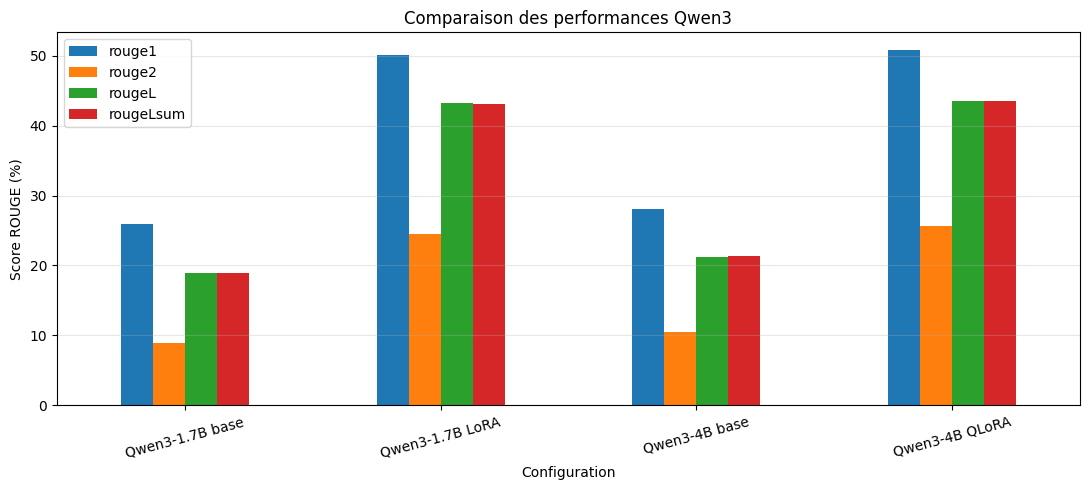

In [40]:

# Compare les quatre configurations.
results = pd.DataFrame({
    "Qwen3-1.7B base": base_scores,
    "Qwen3-1.7B LoRA": ft_scores,
    "Qwen3-4B base": base4_scores,
    "Qwen3-4B QLoRA": qlora_scores
}).T

print("Comparaison des scores ROUGE :")
display(results.round(2))

# Compare les longueurs et les coûts.
comparison = pd.DataFrame({
    "Modèle": [
        "1.7B base", "1.7B LoRA",
        "4B base", "4B QLoRA"
    ],
    "Mots moyens": [
        mean_words(base_summaries),
        mean_words(ft_summaries),
        mean_words(base4_summaries),
        mean_words(qlora_summaries)
    ],
    "Entraînement (min)": [
        0, 6.2, 0, qlora_train_time / 60
    ],
    "Pic GPU (Go)": [
        np.nan, 4.46, np.nan, qlora_peak_gb
    ]
})

display(comparison.round(2))

# Graphique.
results.plot(kind="bar", figsize=(11, 5))
plt.title("Comparaison des performances Qwen3")
plt.ylabel("Score ROUGE (%)")
plt.xlabel("Configuration")
plt.xticks(rotation=15)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


### Mini-projet A — QLoRA sur Qwen3-4B

**1. Quantification et entraînement**

Nous avons chargé Qwen3-4B en utilisant une quantification NF4 sur 4 bits avec double quantification, afin de réduire la consommation mémoire du modèle.

Nous avons ensuite entraîné des adaptateurs LoRA de rang 16 sur 1 000 exemples de DialogSum, pendant une époque, avec un batch effectif de 16.

L'entraînement a nécessité **63 pas d'optimisation**, pour une durée de **19,68 minutes** et un pic de consommation GPU de **8,26 Go** sur une Tesla T4.

Le modèle comptait environ **33 millions de paramètres entraînables**, soit 0,8145 % de ses paramètres.

**2. Comparaison des performances**

| Modèle | ROUGE-1 | ROUGE-2 | ROUGE-L |
|---|---:|---:|---:|
| Qwen3-1.7B base | 25,86 | 8,87 | 18,85 |
| Qwen3-1.7B LoRA | 49,99 | 24,07 | 42,77 |
| Qwen3-4B base | 28,04 | 10,51 | 21,20 |
| Qwen3-4B QLoRA | 50,81 | 25,69 | 43,46 |

Le fine-tuning améliore fortement les scores des deux modèles.

Le résultat le plus intéressant est que **Qwen3-1.7B fine-tuné dépasse largement Qwen3-4B sans fine-tuning**. Cela montre qu'un modèle plus petit mais spécialisé peut être plus performant qu'un modèle plus volumineux sur une tâche précise.

Après QLoRA, Qwen3-4B obtient les meilleurs scores, mais l'amélioration par rapport au 1.7B LoRA reste assez faible : seulement 0,82 point supplémentaire en ROUGE-1.

**3. Comparaison des longueurs**

Les résumés humains contiennent en moyenne 17,12 mots.

Avant fine-tuning, Qwen3-1.7B produit des résumés de 76,7 mots et Qwen3-4B de 74,5 mots.

Après fine-tuning, ces longueurs diminuent à 23,98 mots pour le 1.7B LoRA et 25,1 mots pour le 4B QLoRA.

Les deux modèles ont donc appris à produire des résumés beaucoup plus concis, proches du format attendu par DialogSum.

**4. Compromis qualité/coût**

L'entraînement du 1.7B LoRA a duré 6,2 minutes avec un pic de mémoire de 4,46 Go, contre 19,68 minutes et 8,26 Go pour le 4B QLoRA.

Le modèle 4B nécessite donc environ trois fois plus de temps d'entraînement et presque deux fois plus de mémoire GPU pour un gain ROUGE relativement faible.

Pour une application de résumé de dialogues, je privilégierais donc **Qwen3-1.7B avec LoRA**, car il offre un meilleur compromis entre performances et ressources nécessaires.

Le modèle 4B QLoRA pourrait toutefois être intéressant si une évaluation plus approfondie démontrait une amélioration importante de la fidélité ou de la qualité des résumés.

Ces conclusions restent limitées aux 50 dialogues évalués et ne permettent pas de garantir le même résultat sur d'autres jeux de données.

In [41]:
import os

QLORA_DIR = "qwen3-4b-dialogsum-qlora/adapter"

qlora_model.save_pretrained(QLORA_DIR)
tokenizer4.save_pretrained(QLORA_DIR)

print("Adaptateur QLoRA sauvegardé.")

for name in sorted(os.listdir(QLORA_DIR)):
    path = os.path.join(QLORA_DIR, name)

    if os.path.isfile(path):
        print(
            f"{name:30} "
            f"{os.path.getsize(path) / 1e6:.2f} Mo"
        )

Adaptateur QLoRA sauvegardé.
README.md                      0.01 Mo
adapter_config.json            0.00 Mo
adapter_model.safetensors      132.19 Mo
chat_template.jinja            0.00 Mo
tokenizer.json                 11.42 Mo
tokenizer_config.json          0.00 Mo
